# Classifier for fish Calls


In [1]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import random_split
import torch.nn.functional as F
import random

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Loading the Fake Data

In [2]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), #ensures 1-channel
    transforms.ToTensor(), # changes pixels and shape
    transforms.Normalize(mean=[0.5], std=[0.5])
])

bad_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/random_snips",
    transform=transform
)

loader_bad = DataLoader(bad_dataset, batch_size=8, shuffle=True) #Bigger is better - probably?

In [3]:
print(bad_dataset.class_to_idx)

{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}


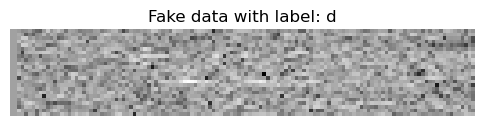

In [4]:
imgs, labels = next(iter(loader_bad))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Fake data with label: {bad_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Loading the Good Data: 

In [5]:
good_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/cnn_snips",
    transform=transform
)


train_size = int(0.8 * len(good_dataset))
val_size = len(good_dataset) - train_size

train_dataset, val_dataset = random_split(good_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

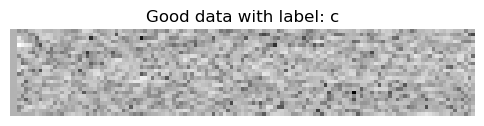

In [6]:
imgs, labels = next(iter(train_loader))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Good data with label: {good_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Initializing CNN

In [7]:
import torch
import random
import torch.nn.functional as F

def augment_spectrogram(x):
    B, C, Freq, Time = x.shape

    # ----- 1. Time masking -----
    if random.random() < 0.7:
        t = random.randint(10, 40)
        t0 = random.randint(0, max(1, Time - t))
        x[:, :, :, t0:t0+t] = 0

    # ----- 2. Frequency masking -----
    if random.random() < 0.7:
        f = random.randint(5, 15)
        f0 = random.randint(0, max(1, Freq - f))
        x[:, :, f0:f0+f, :] = 0

    # ----- 3. Time shift -----
    if random.random() < 0.7:
        shift = random.randint(-20, 20)
        x = torch.roll(x, shifts=shift, dims=-1)

    # ----- 4. Frequency shift -----
    if random.random() < 0.5:
        shift = random.randint(-4, 4)
        x = torch.roll(x, shifts=shift, dims=-2)

    # ----- 5. Random gain -----
    if random.random() < 0.7:
        gain = 0.7 + 0.6 * random.random()   # 0.7–1.3
        x = x * gain

    # ----- 6. Additive Gaussian noise -----
    if random.random() < 0.7:
        noise = 0.015 * torch.randn_like(x)
        x = x + noise

    # ----- 7. Random dynamic range compression -----
    if random.random() < 0.5:
        alpha = random.uniform(0.5, 1.5)
        x = torch.sign(x) * (torch.abs(x) ** alpha)

    # ----- 8. Random cropping (temporal) -----
    if random.random() < 0.5:
        crop = random.randint(0, 10)
        if crop < Time:
            x = x[:, :, :, crop:]

    return x


class ProjectionHead(nn.Module):
    def __init__(self, in_dim=512, proj_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Linear(256, proj_dim)
        )

    def forward(self, x):
        return self.net(x)

from torchvision.models import mobilenet_v3_small

class SimCLR(nn.Module):
    def __init__(self):
        super().__init__()
        base = mobilenet_v3_small(weights=None)
        base.features[0][0] = nn.Conv2d(1, 16, 3, 2, 1, bias=False)
        self.encoder = base.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.projector = ProjectionHead(in_dim=576, proj_dim=128)

    def forward(self, x):
        h = self.encoder(x)
        h = self.pool(h).flatten(1)
        z = self.projector(h)
        return F.normalize(z, dim=1)
        
def byol_loss(p, t):
    p = F.normalize(p, dim=1)
    t = F.normalize(t, dim=1)
    return 2 - 2 * (p * t).sum(dim=1).mean()



import torch
import torch.nn as nn
import torch.nn.functional as F
import copy

class BYOLAudio(nn.Module):
    def __init__(self, base_encoder, proj_dim=128, hidden_dim=256, ema_decay=0.99):
        super().__init__()

        # Online encoder
        self.online_encoder = base_encoder

        # Target encoder (EMA copy)
        self.target_encoder = copy.deepcopy(base_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        # Projector
        self.projector = nn.Sequential(
            nn.Linear(512, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, proj_dim)
        )

        # Predictor (online only)
        self.predictor = nn.Sequential(
            nn.Linear(proj_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, proj_dim)
        )

        self.ema_decay = ema_decay

    def forward(self, x1, x2):
        # Online branch
        o1 = self.online_encoder(x1).flatten(1)
        o2 = self.online_encoder(x2).flatten(1)

        z1 = self.projector(o1)
        z2 = self.projector(o2)

        p1 = self.predictor(z1)
        p2 = self.predictor(z2)

        # Target branch (no grad)
        with torch.no_grad():
            t1 = self.projector(self.target_encoder(x1).flatten(1))
            t2 = self.projector(self.target_encoder(x2).flatten(1))

        return p1, p2, t1.detach(), t2.detach()

    @torch.no_grad()
    def update_target(self):
        for online_p, target_p in zip(self.online_encoder.parameters(),
                                      self.target_encoder.parameters()):
            target_p.data = (
                self.ema_decay * target_p.data +
                (1 - self.ema_decay) * online_p.data
            )


### Perform Pretraining

In [8]:
from torchvision.models import resnet18


def pretrain_byol(model, loader, optimizer, epochs=50):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for imgs, _ in loader:
            imgs = imgs.to(device)

            x1 = augment_spectrogram(imgs.clone())
            x2 = augment_spectrogram(imgs.clone())

            p1, p2, t1, t2 = model(x1, x2)

            loss = byol_loss(p1, t2) + byol_loss(p2, t1)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            model.update_target()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs}  BYOL Loss: {total_loss/len(loader):.4f}")
        
base = resnet18(weights=None)
base.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)
encoder = nn.Sequential(*list(base.children())[:-1])

byol = BYOLAudio(encoder).to(device)
optimizer = torch.optim.Adam(byol.parameters(), lr=1e-3)
pretrain_byol(byol, loader_bad, optimizer, epochs=50)

torch.save(byol.online_encoder.state_dict(), "byol_encoder.pth")


Epoch 1/50  BYOL Loss: 0.1204
Epoch 2/50  BYOL Loss: 0.0001
Epoch 3/50  BYOL Loss: 0.0001
Epoch 4/50  BYOL Loss: 0.0001
Epoch 5/50  BYOL Loss: 0.0001
Epoch 6/50  BYOL Loss: 0.0004
Epoch 7/50  BYOL Loss: 0.0331
Epoch 8/50  BYOL Loss: 0.0553
Epoch 9/50  BYOL Loss: 0.0493
Epoch 10/50  BYOL Loss: 0.0518
Epoch 11/50  BYOL Loss: 0.0519
Epoch 12/50  BYOL Loss: 0.0483
Epoch 13/50  BYOL Loss: 0.0456
Epoch 14/50  BYOL Loss: 0.0400
Epoch 15/50  BYOL Loss: 0.0482
Epoch 16/50  BYOL Loss: 0.0425
Epoch 17/50  BYOL Loss: 0.0417
Epoch 18/50  BYOL Loss: 0.0492
Epoch 19/50  BYOL Loss: 0.0508
Epoch 20/50  BYOL Loss: 0.0485
Epoch 21/50  BYOL Loss: 0.0464
Epoch 22/50  BYOL Loss: 0.0513
Epoch 23/50  BYOL Loss: 0.0464
Epoch 24/50  BYOL Loss: 0.0451
Epoch 25/50  BYOL Loss: 0.0675
Epoch 26/50  BYOL Loss: 0.0587
Epoch 27/50  BYOL Loss: 0.0552
Epoch 28/50  BYOL Loss: 0.0724
Epoch 29/50  BYOL Loss: 0.0622
Epoch 30/50  BYOL Loss: 0.0623
Epoch 31/50  BYOL Loss: 0.0613
Epoch 32/50  BYOL Loss: 0.0673
Epoch 33/50  BYOL

### Actual Training: 

In [15]:
def fit(model, train_loader, optimizer, criterion, epochs, val_loader=None, scheduler=None):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for imgs, labels in train_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if scheduler is not None:
            scheduler.step()

        print(f"Epoch {epoch+1}/{epochs}  Train Loss: {total_loss/len(train_loader):.4f}")

        # Optional validation
        if val_loader is not None:
            model.eval()
            correct = 0
            total = 0
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device)
                    preds = model(imgs).argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)
            acc = correct / total
            print(f"  Val Acc: {acc:.4f}")
            model.train()

# -----------------------------
# Build fine-tuning model
# -----------------------------
base = resnet18(weights=None)
base.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)

# Extract encoder (same structure as BYOL)
finetune_encoder = nn.Sequential(*list(base.children())[:-1])

# Load pretrained BYOL encoder weights
state = torch.load("byol_encoder.pth", weights_only=True)
finetune_encoder.load_state_dict(state)

total = sum(p.numel() for p in finetune_model.parameters())
trainable = sum(p.numel() for p in finetune_model.parameters() if p.requires_grad)
print("Total params:", total)
print("Trainable params:", trainable)

# Build full classifier model
class FineTuneModel(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.fc = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 5)
        )

    def forward(self, x):
        h = self.encoder(x)          # [B, 512, 1, 1]
        h = h.flatten(1)             # [B, 512]
        return self.fc(h)

finetune_model = FineTuneModel(finetune_encoder).to(device)

finetune_model = finetune_model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1) #try more loss methods

optimizer = torch.optim.Adam([
    {"params": finetune_model.encoder.parameters(), "lr": 1e-4},
    {"params": finetune_model.fc.parameters(), "lr": 1e-3},
])


scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=50, eta_min=1e-6
)

fit(
    finetune_model,
    train_loader,
    optimizer,
    criterion,
    epochs=100,
    val_loader=val_loader,
    scheduler=scheduler
)

Total params: 11300293
Trainable params: 11300293
Epoch 1/100  Train Loss: 1.4989
  Val Acc: 0.4800
Epoch 2/100  Train Loss: 1.4055
  Val Acc: 0.5000
Epoch 3/100  Train Loss: 1.3719
  Val Acc: 0.3600
Epoch 4/100  Train Loss: 1.3906
  Val Acc: 0.4800
Epoch 5/100  Train Loss: 1.3421
  Val Acc: 0.4600
Epoch 6/100  Train Loss: 1.2975
  Val Acc: 0.4400
Epoch 7/100  Train Loss: 1.2900
  Val Acc: 0.5000
Epoch 8/100  Train Loss: 1.2999
  Val Acc: 0.5000
Epoch 9/100  Train Loss: 1.2996
  Val Acc: 0.4400
Epoch 10/100  Train Loss: 1.3255
  Val Acc: 0.3800
Epoch 11/100  Train Loss: 1.3198
  Val Acc: 0.5000
Epoch 12/100  Train Loss: 1.3071
  Val Acc: 0.5000
Epoch 13/100  Train Loss: 1.3199
  Val Acc: 0.4600
Epoch 14/100  Train Loss: 1.2920
  Val Acc: 0.5000
Epoch 15/100  Train Loss: 1.2762
  Val Acc: 0.4800
Epoch 16/100  Train Loss: 1.3326
  Val Acc: 0.4800
Epoch 17/100  Train Loss: 1.2746
  Val Acc: 0.4600
Epoch 18/100  Train Loss: 1.2811
  Val Acc: 0.4600
Epoch 19/100  Train Loss: 1.2764
  Val Ac

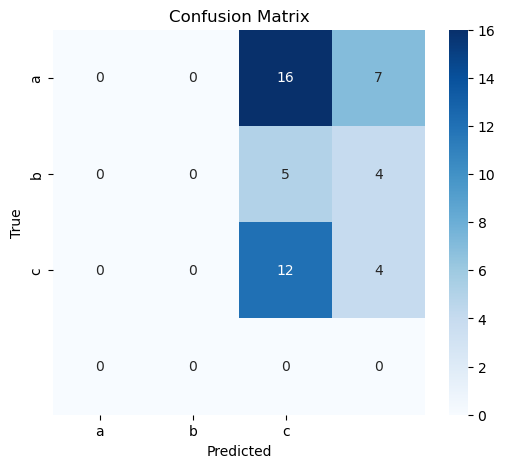

In [11]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(finetune_model, val_loader)
# keep only classes 0, 1, 2
mask = y_true < 3

y_true_filtered = y_true[mask]
y_pred_filtered = y_pred[mask]

cm = confusion_matrix(y_true_filtered, y_pred_filtered)

class_names = ["a", "b", "c"]  # adjust if needed

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
